In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1
import matplotlib.pyplot as plt

In [14]:
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    # Design the analog Butterworth filter
    analog_b, analog_a = butter(
        filter_order, cutoff_frequency, analog=True, btype='low'
    )
    print(analog_b)
    print(analog_a)
    # Perform the bilinear transformation

    digital_b, digital_a = bilinear(
        analog_b, analog_a, sampling_frequency
    )

    return digital_b, digital_a

In [15]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000

In [16]:
design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency)

[1.e+12]
[1.00000000e+00 2.61312593e+03 3.41421356e+06 2.61312593e+09
 1.00000000e+12]


(array([1.29607191e-05, 5.18428766e-05, 7.77643148e-05, 5.18428766e-05,
        1.29607191e-05]),
 array([ 1.        , -3.67388572,  5.07378356, -3.12116011,  0.72146964]))

In [17]:
# Design the Butterworth filter
digital_b, digital_a = design_butterworth_filter(
    filter_order, cutoff_frequency, sampling_frequency
)

[1.e+12]
[1.00000000e+00 2.61312593e+03 3.41421356e+06 2.61312593e+09
 1.00000000e+12]


In [18]:
frequency, magnitude_response = freqz(
        digital_b, digital_a, fs=sampling_frequency
    )
print(frequency)
print(magnitude_response)

[   0.        7.8125   15.625    23.4375   31.25     39.0625   46.875
   54.6875   62.5      70.3125   78.125    85.9375   93.75    101.5625
  109.375   117.1875  125.      132.8125  140.625   148.4375  156.25
  164.0625  171.875   179.6875  187.5     195.3125  203.125   210.9375
  218.75    226.5625  234.375   242.1875  250.      257.8125  265.625
  273.4375  281.25    289.0625  296.875   304.6875  312.5     320.3125
  328.125   335.9375  343.75    351.5625  359.375   367.1875  375.
  382.8125  390.625   398.4375  406.25    414.0625  421.875   429.6875
  437.5     445.3125  453.125   460.9375  468.75    476.5625  484.375
  492.1875  500.      507.8125  515.625   523.4375  531.25    539.0625
  546.875   554.6875  562.5     570.3125  578.125   585.9375  593.75
  601.5625  609.375   617.1875  625.      632.8125  640.625   648.4375
  656.25    664.0625  671.875   679.6875  687.5     695.3125  703.125
  710.9375  718.75    726.5625  734.375   742.1875  750.      757.8125
  765.625   773.43

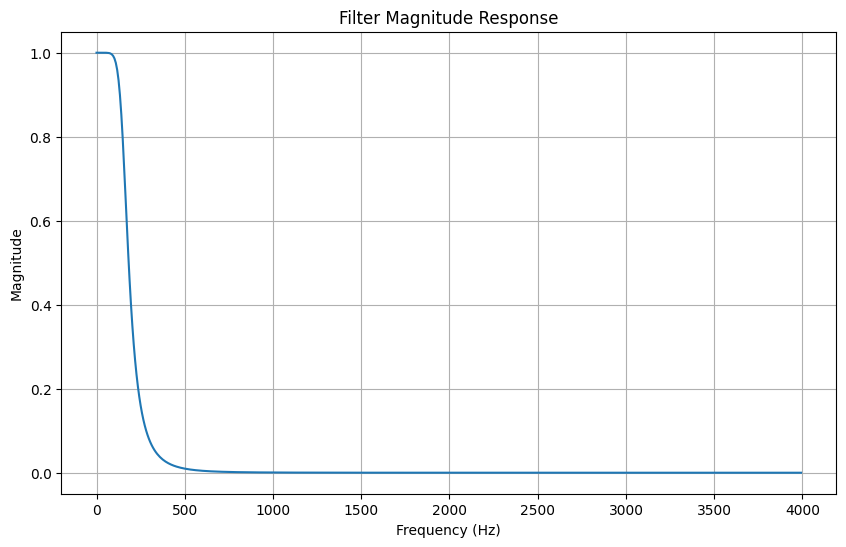

In [19]:
plt.figure(figsize=(10, 6))
plt.plot(frequency, np.abs(magnitude_response))
# plt.plot(frequency,20*np.log10(abs(magnitude_response)))
plt.title('Filter Magnitude Response')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid(True)
plt.show()

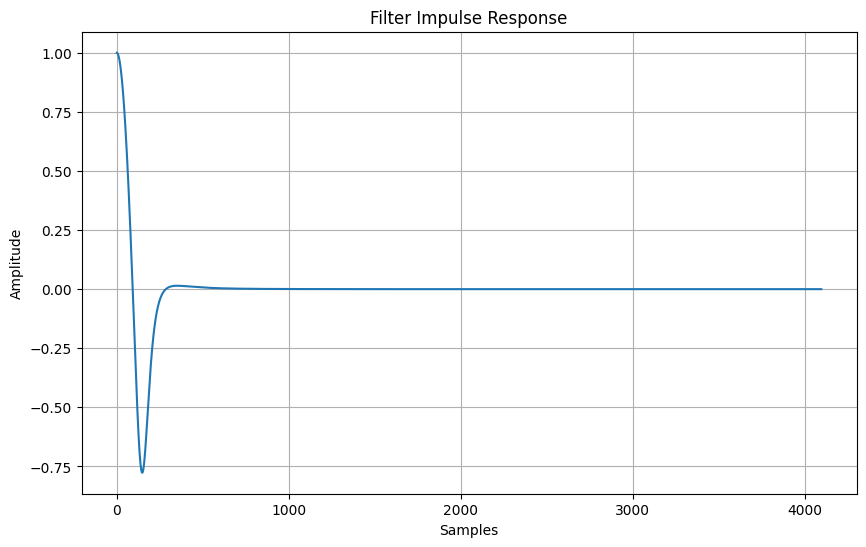

In [20]:
magnitude_response2, impulse_response = freqz(
        digital_b, digital_a, worN=4096
    )

# Plot the impulse response
plt.figure(figsize=(10, 6))
plt.plot(impulse_response.real)
plt.title('Filter Impulse Response')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

In [21]:
def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    # Design the analog Chebyshev filter
    analog_b, analog_a = cheby1(
        filter_order, ripple, cutoff_frequency,
        analog=True, btype='low'
    )

    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(
        analog_b, analog_a, sampling_frequency
    )

    return digital_b, digital_a

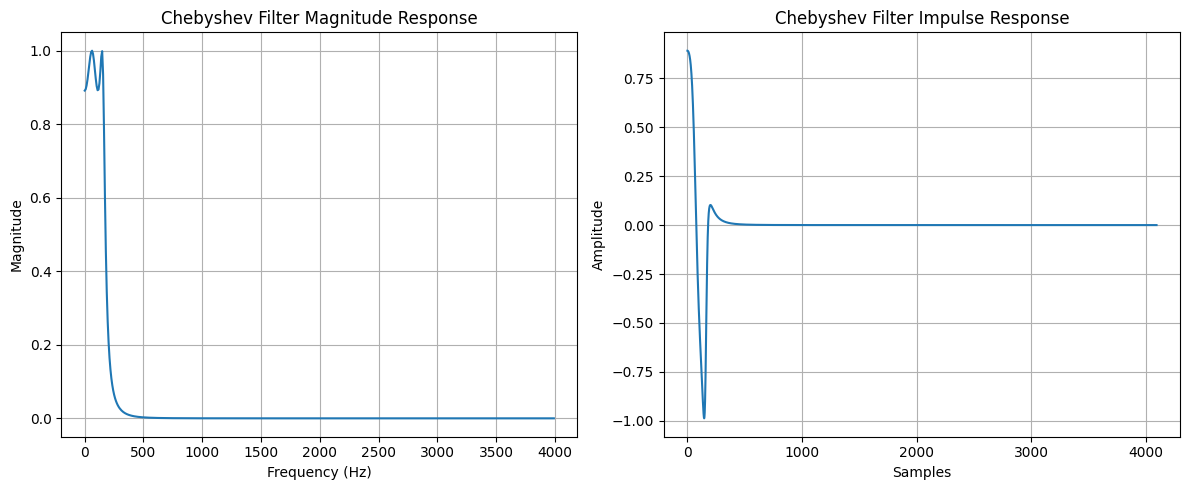

Filter coefficients saved at: filter_coefficients.txt


In [22]:
ripple = 1  # 1 dB ripple in the passband

def plot_filter_response(b, a, fs):
    # Magnitude Response
    freq, h = freqz(b, a, fs=fs)
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(freq, np.abs(h))
    plt.title('Chebyshev Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)

    # Impulse Response
    _, impulse = freqz(b, a, worN=4096)
    plt.subplot(1, 2, 2)
    plt.plot(impulse.real)
    plt.title('Chebyshev Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

digital_b, digital_a = design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple)
plot_filter_response(digital_b, digital_a, sampling_frequency)

# Save the filter coefficients
filter_path = 'filter_coefficients.txt'
np.savetxt(filter_path, np.vstack((digital_b, digital_a)), delimiter=',')
print(f"Filter coefficients saved at: {filter_path}")

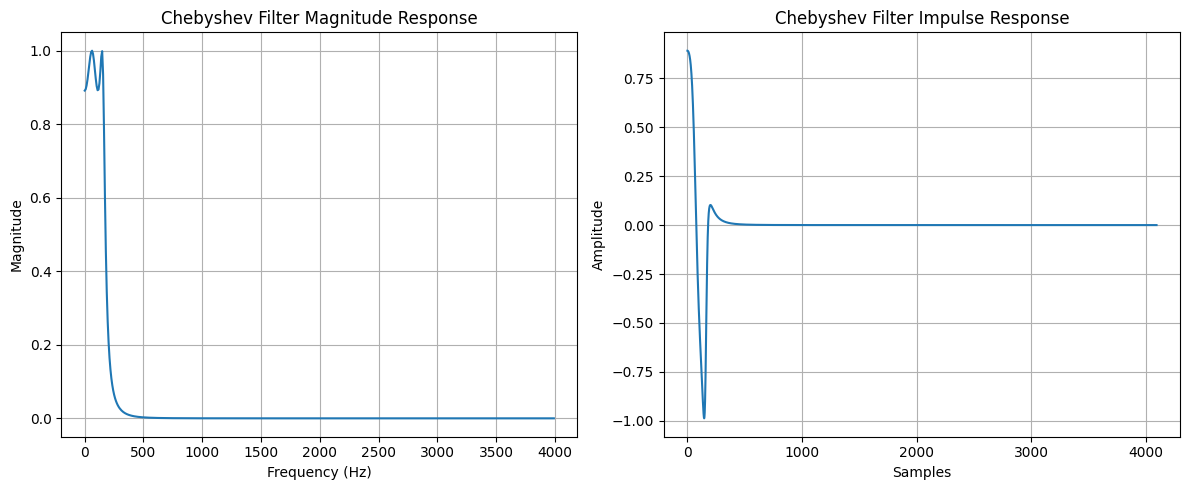

In [23]:
# Use parameters from previous cells
ripple_value = 1.0  # 1 dB ripple in the passband

# Design the Chebyshev filter
dig_b, dig_a = design_chebyshev_filter(
    filter_order=filter_order,
    cutoff_frequency=cutoff_frequency,
    sampling_frequency=sampling_frequency,
    ripple=ripple_value
)

# Plot the response using the helper function
plot_filter_response(dig_b, dig_a, sampling_frequency)

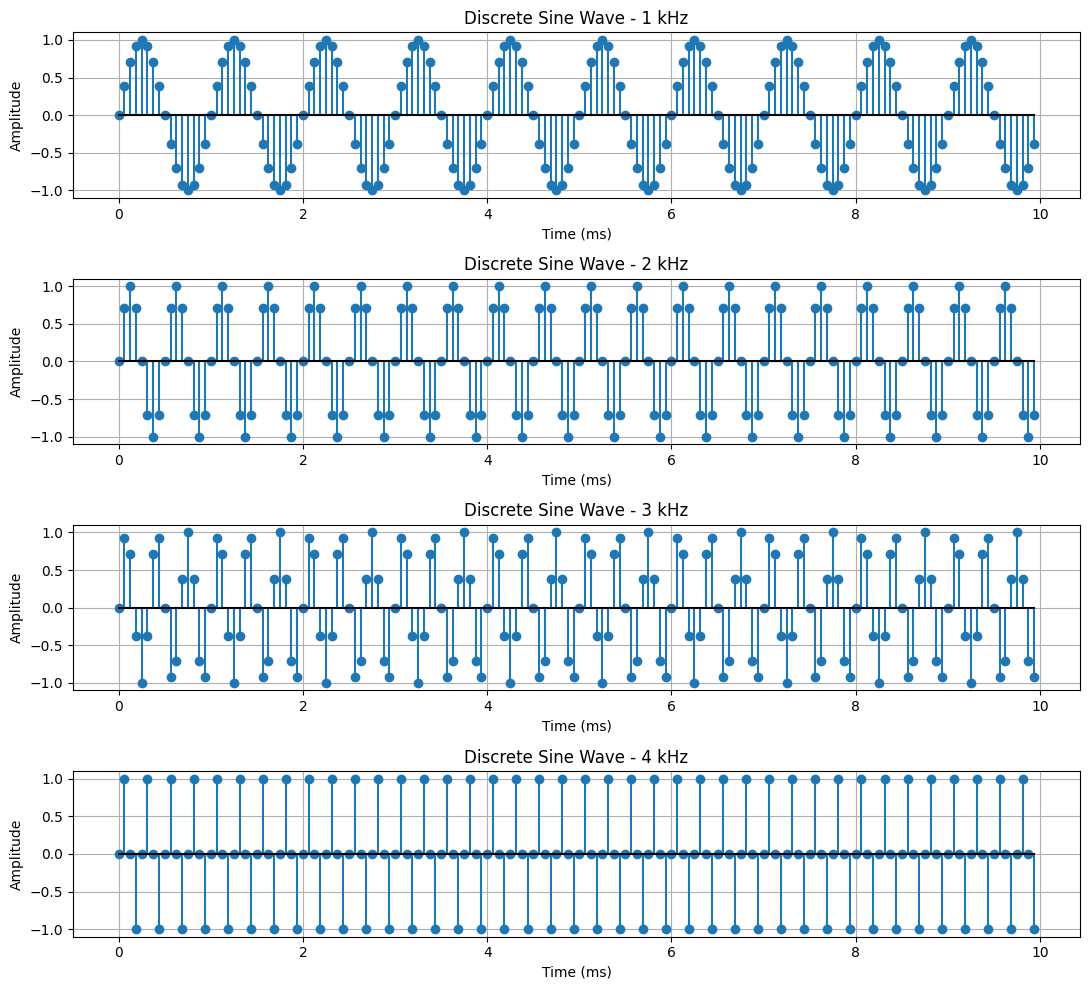

In [24]:
import numpy as np
import matplotlib.pyplot as plt

fs = 16000
duration = 0.01
frequencies = [1000, 2000, 3000, 4000]
t = np.arange(0, duration, 1 / fs)

fig, axes = plt.subplots(4, 1, figsize=(11, 10))

for ax, f in zip(axes, frequencies):
    x = np.sin(2 * np.pi * f * t)
    ax.stem(t * 1000, x, basefmt="k-")
    ax.set_title(f"Discrete Sine Wave - {f // 1000} kHz")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

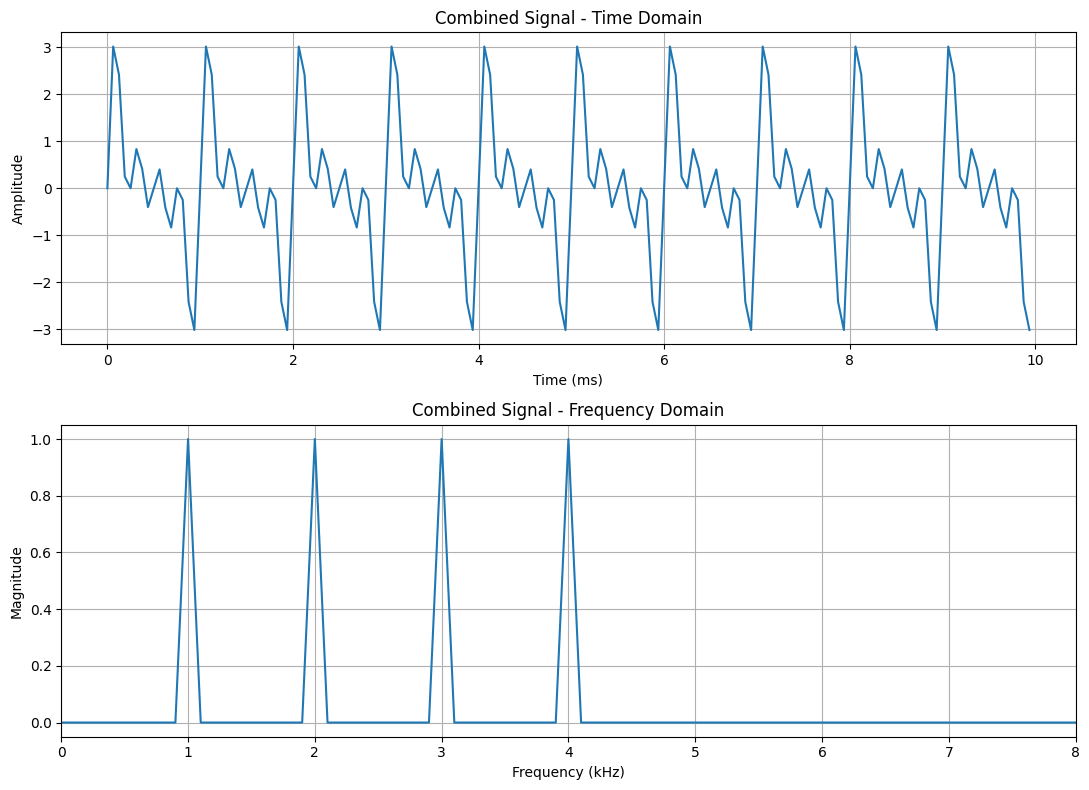

In [25]:
# Add all 4 sine waves...
combined_signal = sum(np.sin(2 * np.pi * f * t) for f in frequencies)

spectrum = np.fft.rfft(combined_signal)
freq_axis = np.fft.rfftfreq(len(combined_signal), d=1 / fs)
magnitude = np.abs(spectrum) / len(combined_signal)
magnitude[1:-1] *= 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(t * 1000, combined_signal)
axes[0].set_title("Combined Signal - Time Domain")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(freq_axis / 1000, magnitude)
axes[1].set_title("Combined Signal - Frequency Domain")
axes[1].set_xlabel("Frequency (kHz)")
axes[1].set_ylabel("Magnitude")
axes[1].grid(True)
axes[1].set_xlim(0, fs / 2000)

plt.tight_layout()
plt.show()

Numerator coefficients: [0.0009335  0.00373399 0.00560099 0.00373399 0.0009335 ]
Denominator coefficients: [ 1.         -2.97684433  3.42230953 -1.7861066   0.35557738]


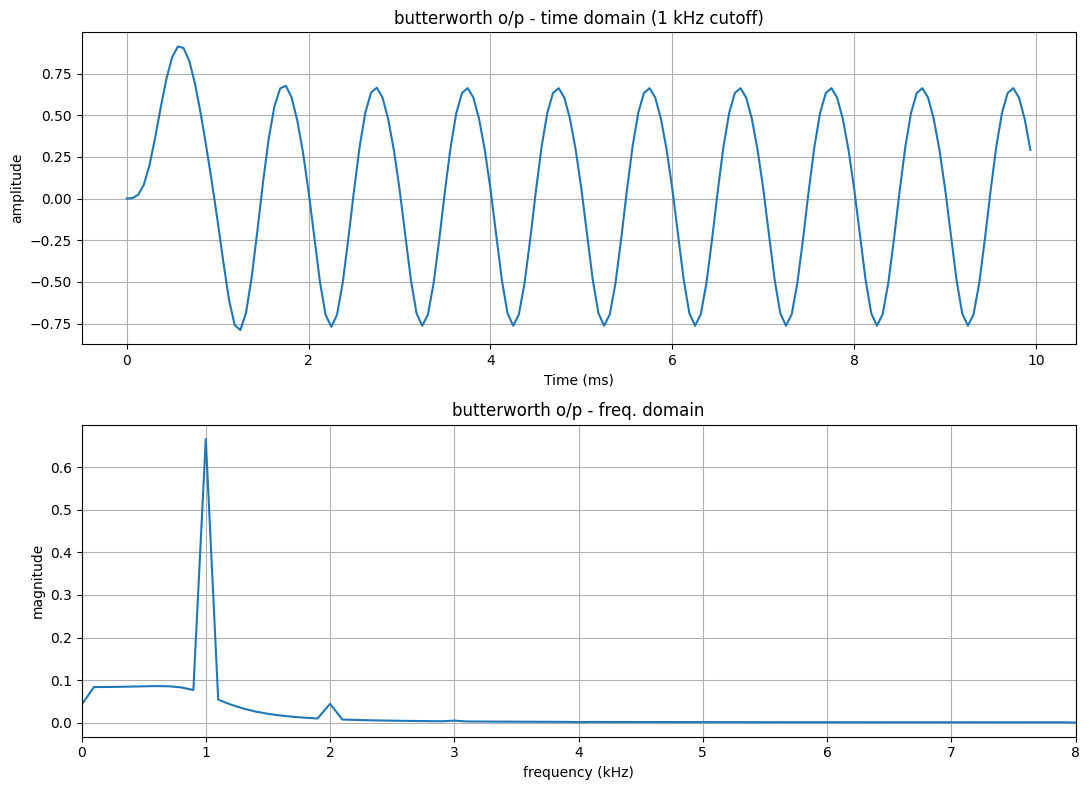

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter

# apply Butterworth filter (iirfilter)
cutoff = 1000
filter_order = 4
b, a = butter(filter_order, cutoff, btype="low", fs=fs)
output = lfilter(b, a, combined_signal)

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

spectrum = np.fft.rfft(output)
freq_axis = np.fft.rfftfreq(len(output), d=1 / fs)
magnitude = np.abs(spectrum) / len(output)
magnitude[1:-1] *= 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
axes[0].plot(t * 1000, output)
axes[0].set_title(f"butterworth o/p - time domain ({cutoff // 1000} kHz cutoff)")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("amplitude")
axes[0].grid(True)

axes[1].plot(freq_axis / 1000, magnitude)
axes[1].set_title("butterworth o/p - freq. domain")
axes[1].set_xlabel("frequency (kHz)")
axes[1].set_ylabel("magnitude")
axes[1].grid(True)
axes[1].set_xlim(0, fs / 2000)

plt.tight_layout()
plt.show()

Numerator coefficients: [0.02419539 0.09678157 0.14517236 0.09678157 0.02419539]
Denominator coefficients: [ 1.         -1.58955579  1.66900162 -0.9190694   0.24968852]


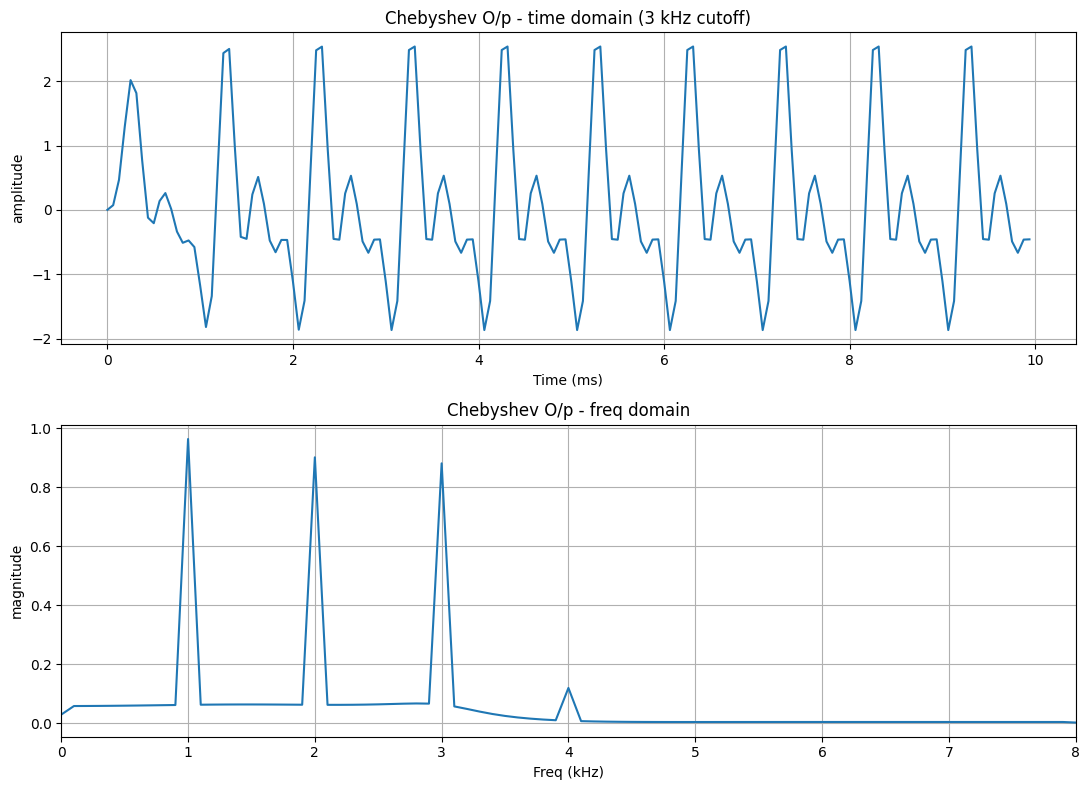

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import cheby1, lfilter

# Define filter parameters
filter_order = 4
ripple = 0.5  # 0.5 dB ripple in the passband
cutoff = 3000 # 3 kHz cutoff

# apply Chebyshev Type1 filter
b, a = cheby1(filter_order, ripple, cutoff, btype="low", fs=fs)
output = lfilter(b, a, combined_signal)

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

# single-sided amplitude spectrum
spectrum = np.fft.rfft(output)
freq_axis = np.fft.rfftfreq(len(output), d=1 / fs)
magnitude = np.abs(spectrum) / len(output)
magnitude[1:-1] *= 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(t * 1000, output)
axes[0].set_title(f"Chebyshev O/p - time domain ({cutoff // 1000} kHz cutoff)")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("amplitude")
axes[0].grid(True)

axes[1].plot(freq_axis / 1000, magnitude)
axes[1].set_title("Chebyshev O/p - freq domain")
axes[1].set_xlabel("Freq (kHz)")
axes[1].set_ylabel("magnitude")
axes[1].grid(True)
axes[1].set_xlim(0, fs / 2000)

plt.tight_layout()
plt.show()